# Практическое задание 1. Вероятность дефолта по автокредиту

**Дисциплина «ИИ и машинное обучение»** · НИУ ВШЭ, Высшая школа бизнеса

Магистратура «Бизнес-аналитика и цифровые решения в финансах»

---

Банк выдаёт кредиты на покупку автомобиля. По каждой заявке известны
сумма кредита, цена машины, анкета заёмщика и его кредитная история из
бюро. Нужно с помощью **логистической регрессии** оценить вероятность
того, что заёмщик уйдёт в дефолт, и решить по каждой заявке из вашего
теста: **одобрить или отказать**.

У каждого свой вариант: свой набор заявок в скрытом тесте и своя
экономика. Номер варианта смотрите в файле `распределение_вариантов_по_студентам.xlsx` в нашем чате.

Что требуется, как считаются деньги портфеля и как ставится
оценка — в тексте задания. Здесь только данные, место под решение
и готовая сборка файла сдачи.

**Что сдать:** этот ноутбук `ФАМИЛИЯ_ИО.ipynb` с выполненными ячейками и файл
`ФАМИЛИЯ_ИО_predictions.csv` с результатами.

## Данные

Данные лежат на Яндекс Диске: https://disk.yandex.ru/d/wjsVUGFFIC2lCQ

Скачайте оттуда три файла и положите рядом с ноутбуком.

| Файл | Что внутри |
|---|---|
| `dataset.csv` | 60 000 заявок со столбцом `дефолт` — на них вы учитесь |
| `test_NN.csv` | 2 000 заявок вашего варианта, **без ответа** |
| `profit_loss.csv` | `доход_с_клиента` и `доля_возврата` всех вариантов — берите строку своего |

`NN` — номер вашего варианта двумя цифрами: `test_07.csv`, например.

В тесте 40 столбцов, в обучающем файле на один больше — `дефолт` (то, что хотим предсказывать).
Полное описание каждого столбца смотрите в [README.md](https://github.com/Rimest/ml_ai_course_gsb_hse/blob/main/homeworks/hw1_credit_default/README.md).

## Решение

Первая ячейка — преамбула: она фиксирует сид случайности. Выполните её
и подставляйте `SEED` везде, где есть параметр `random_state`. Ноутбук
должен при повторном запуске сверху вниз давать те же числа: результат должен быть воспроизводим.

In [1]:
## ── воспроизводимость ──────────────────────────────────────────────
import random

import numpy as np

ФАМИЛИЯ_ИО = 'РУБАН_ИС' # Например, 'ИВАНОВ_ИИ'
SEED = 48
ВАРИАНТ = 48
random.seed(SEED)      # стандартный модуль random
np.random.seed(SEED)   # numpy

# Своего генератора у pandas и scikit-learn нет — оба берут случайность
# из numpy, так что строка выше покрывает и их. Но там, где параметр
# random_state есть, передавайте SEED явно: тогда результат не зависит
# ещё и от порядка, в котором выполнялись ячейки.

### Шаг 1. Загрузка данных и экономика варианта

Загружаю обучающую выборку, свой тест и строку варианта 48 из `profit_loss.csv`

In [2]:
# библиотеки
import pandas as pd                     # таблицы
import matplotlib.pyplot as plt         # графики
from sklearn.linear_model import LogisticRegression          # сама модель
from sklearn.preprocessing import StandardScaler, SplineTransformer  # масштаб признаков и сплайны (шаг 4)
from sklearn.model_selection import StratifiedKFold          # деление данных на 5 частей для проверки
from sklearn.metrics import roc_auc_score                    # метрика качества, по ней ставят баллы

# читаю три файла, они должны лежать в той же папке что и тетрадка
data = pd.read_csv("dataset.csv")                 # 60 000 заявок, по ним известно был дефолт или нет
test = pd.read_csv(f"test_{ВАРИАНТ:02d}.csv")     # мои 2 000 заявок, ответа нет. {ВАРИАНТ:02d} превращает 48 в "48" (а 7 было бы "07")
econ = pd.read_csv("profit_loss.csv").set_index("вариант").loc[ВАРИАНТ]  # из таблицы всех вариантов беру строку 48

# две цифры экономики моего варианта
ДОХОД = float(econ["доход_с_клиента"])   # 2400 - столько банк зарабатывает на клиенте который вернул кредит
ВОЗВРАТ = float(econ["доля_возврата"])   # 0.55 - при дефолте банк продаёт машину и получает 55% её цены

# y это ответ, который модель учится угадывать: 1 = дефолт, 0 = нормально заплатил
y = data["дефолт"]

# проверка что всё загрузилось. shape = (строк, столбцов)
print("Обучающая выборка:", data.shape, " тест:", test.shape)
print("Доход с клиента:", ДОХОД, " доля возврата:", ВОЗВРАТ)
print("Доля дефолтов в обучающей выборке: %.2f %%" % (100 * y.mean()))   # среднее от 0 и 1 = доля единиц

Обучающая выборка: (60000, 41)  тест: (2000, 40)
Доход с клиента: 2400.0  доля возврата: 0.55
Доля дефолтов в обучающей выборке: 21.75 %


Сначала посмотрю сколько банк теряет на одном дефолте. Формула из задания: `max(сумма_кредита - доля_возврата × цена_машины, 0)`.
Если кредит меньше 55% цены машины, то продажа залога покрывает долг и дефолт банку ничего не стоит

In [3]:
# функция убытка: сколько банк теряет если этот клиент уйдёт в дефолт
# сумма кредита минус то что банк выручит за машину (55% цены)
# np.maximum(..., 0) - если выручка больше долга, убыток 0, а не минус
def убыток(df):
    return np.maximum(df["сумма_кредита"] - ВОЗВРАТ * df["цена_машины"], 0)

loss_train = убыток(data)   # убыток по каждой из 60 000 заявок
print(loss_train.describe().round(0))   # describe = среднее, мин, макс, квартили
print("Заявок, где дефолт не приносит убытка: %.1f %%" % (100 * (loss_train == 0).mean()))

# что будет если одобрять всех подряд:
# (y == 0) это 1 у тех кто заплатил -> по ним получаем ДОХОД
# (y == 1) это 1 у дефолтных -> по ним теряем убыток
# потом всё суммирую и пересчитываю с 60 000 заявок на 2 000, чтобы было в масштабе моего теста
всё_одобрить = (ДОХОД * (y == 0) - loss_train * (y == 1)).sum() * 2000 / len(data)
print("Одобрить всех: %.0f на 2 000 заявок" % всё_одобрить)

count     60000.0
mean      13236.0
std        7031.0
min           0.0
25%        8679.0
50%       14285.0
75%       18479.0
max      107953.0
dtype: float64
Заявок, где дефолт не приносит убытка: 8.4 %
Одобрить всех: -2633901 на 2 000 заявок


Средний убыток от дефолта ~13 тыс, это в 5-6 раз больше чем доход с хорошего клиента (2 400). А дефолтов каждый пятый. Поэтому если одобрять всех, банк в минусе. Надо отбирать

Дальше проверяю что тест похож на обучающую выборку: те же даты? есть ли пропуски? встречаются ли в тесте те же отделения, салоны и сотрудники?

In [4]:
# 1) пропуски: isna() даёт True где пусто, sum() считает сколько их в каждом столбце
#    [lambda s: s > 0] оставляет только столбцы где пропуски есть
print("Пропуски в обучающей выборке:")
print(data.isna().sum()[lambda s: s > 0])
print("Пропуски в тесте:", int(test.isna().sum().sum()))
print()

# 2) месяцы выдачи. дата записана как "01-08-18", str[3:] отрезает день и оставляет "08-18"
print("Месяцы выдачи, обучение:", sorted(data["дата_выдачи"].str[3:].unique()))
print("Месяцы выдачи, тест:    ", sorted(test["дата_выдачи"].str[3:].unique()))
print()

# 3) для каждого столбца с кодами: сколько разных кодов в обучении
#    и какая доля заявок теста имеет код, который в обучении уже встречался (isin = "есть ли в списке")
for col in ["отделение", "продавец", "марка", "индекс", "регион", "сотрудник"]:
    print("%-10s  уникальных в обучении: %5d   доля теста с известным кодом: %.3f"
          % (col, data[col].nunique(), test[col].isin(data[col]).mean()))

Пропуски в обучающей выборке:
занятость    7661
dtype: int64
Пропуски в тесте: 0

Месяцы выдачи, обучение: ['08-18', '09-18', '10-18']
Месяцы выдачи, тест:     ['08-18', '09-18', '10-18']

отделение   уникальных в обучении:    82   доля теста с известным кодом: 1.000
продавец    уникальных в обучении:  2653   доля теста с известным кодом: 0.994
марка       уникальных в обучении:    10   доля теста с известным кодом: 1.000
индекс      уникальных в обучении:  5361   доля теста с известным кодом: 0.980
регион      уникальных в обучении:    22   доля теста с известным кодом: 1.000
сотрудник   уникальных в обучении:  3144   доля теста с известным кодом: 0.996


Что видно:

* пропуски только в `занятость` (~13%, и только в обучающей выборке). Их делаю отдельной категорией
* тест из тех же месяцев что и обучение, август - октябрь 2018
* почти все коды отделений, салонов, индексов и сотрудников из теста есть в обучении. Значит по ним можно посчитать долю дефолтов в прошлом, это пригодится в шаге 3

### Шаг 2. Признаки

Логрегрессия принимает только числа, и ей плохо когда в признаке огромные выбросы. Что я сделала:

* из дат - **возраст** заёмщика на момент выдачи и **день месяца** выдачи
* строки типа `3yrs 6mon` перевела в месяцы
* все суммы (кредит, цена, остатки, платежи) через **логарифм**, тк разброс там от 0 до десятков миллионов
* доли: кредит к цене, доля просроченных и активных счетов, остаток к выданному
* **доля долга, которую не покроет продажа машины** - она напрямую связана с убытком банка
* `описание_бюро` свела к букве рейтинга (A...M) + группы "нет истории" и "не оценён", потом в флаги 0/1

`клиент` не беру вообще, это просто номер заявки

In [5]:
# вспомогательная функция: "3yrs 6mon" -> 3*12 + 6 = 42 месяца
# str.extract достаёт из строки число перед "yrs" и число перед "mon"
def в_месяцы(s):
    """'3yrs 6mon' -> 42"""
    годы = s.str.extract(r"(\d+)yrs")[0].astype(int)
    мес = s.str.extract(r"(\d+)mon")[0].astype(int)
    return 12 * годы + мес


# логарифм для сумм. обычный log ломается на 0 и на минусах, поэтому:
# log1p(x) = log(1 + x) - для нуля даёт 0
# abs + sign - берём логарифм от модуля и возвращаем знак обратно (есть пара отрицательных остатков)
def лог_со_знаком(x):
    """логарифм, который не ломается на нулях и редких отрицательных остатках"""
    return np.sign(x) * np.log1p(np.abs(x))


# главная функция шага: берёт таблицу заявок и возвращает таблицу признаков X (только числа)
# её же потом применяю и к тесту, поэтому признаки у обучения и теста считаются одинаково
def базовые_признаки(df):
    X = pd.DataFrame(index=df.index)   # пустая таблица с теми же строками, сюда складываю признаки

    # ДАТЫ
    # дата выдачи из текста "01-08-18" в настоящую дату
    выдача = pd.to_datetime(df["дата_выдачи"], format="%d-%m-%y")
    # год рождения записан двумя цифрами. "85" это 1985, а "00"..."18" это 2000-е
    # (пандас сам решил бы что "68" это 2068, поэтому век подставляю руками)
    гг = df["дата_рождения"].str[-2:].astype(int)
    век = np.where(гг <= 18, "20", "19")
    рождение = pd.to_datetime(df["дата_рождения"].str[:6] + век + df["дата_рождения"].str[-2:],
                              format="%d-%m-%Y")
    X["возраст"] = (выдача - рождение).dt.days / 365.25   # разница в днях -> в годах
    X["день_выдачи"] = выдача.dt.day
    X["месяц_выдачи"] = выдача.dt.month

    # СДЕЛКА
    X["лог_кредит"] = np.log(df["сумма_кредита"])
    X["лог_цена"] = np.log(df["цена_машины"])
    X["кредит_к_цене"] = df["кредит_к_цене"]                              # как в исходных данных, в %
    X["кредит_к_цене_наш"] = df["сумма_кредита"] / df["цена_машины"]      # пересчитала сама, в исходном почти везде немного не сходится
    X["доля_непокрытия"] = убыток(df) / df["сумма_кредита"]              # какую часть долга не покроет продажа машины

    # ЗАЁМЩИК
    # документы уже 0/1, беру как есть
    for c in ["есть_телефон", "есть_удостоверение", "есть_инн",
              "есть_избирательный", "есть_права", "есть_загранпаспорт"]:
        X[c] = df[c]
    # занятость текстом -> два флага. (условие).astype(int) даёт 1 если правда и 0 если нет
    X["самозанятый"] = (df["занятость"] == "Self employed").astype(int)
    X["занятость_нет_данных"] = df["занятость"].isna().astype(int)   # пропуск тоже информация

    # КРЕДИТНАЯ ИСТОРИЯ
    X["скор_бюро"] = df["скор_бюро"]
    X["нет_скора"] = (df["скор_бюро"] == 0).astype(int)   # 0 значит "нет оценки", а не "очень плохая оценка", поэтому отдельный флаг
    X["возраст_счетов_мес"] = в_месяцы(df["средний_возраст_счетов"])
    X["длина_истории_мес"] = в_месяцы(df["длина_истории"])
    # счётчики (сколько запросов, счетов, просрочек) - через log1p, тк бывают очень большие
    for c in ["запросов_в_бюро", "новых_счетов_6мес", "просрочек_6мес",
              "осн_счетов", "осн_активных", "осн_просроченных", "созаём_счетов"]:
        X["лог_" + c] = np.log1p(df[c])
    # суммы по счетам - через логарифм со знаком
    for c in ["осн_остаток", "осн_одобрено", "осн_выдано", "осн_платёж", "созаём_остаток"]:
        X["лог_" + c] = лог_со_знаком(df[c])
    # доли. если счетов 0 - делить нельзя, поэтому 0 -> nan (пусто), а в конце пустое -> 0
    счетов = df["осн_счетов"].replace(0, np.nan)
    X["доля_просроченных"] = (df["осн_просроченных"] / счетов).fillna(0)
    X["доля_активных"] = (df["осн_активных"] / счетов).fillna(0)
    # остаток к выданному. clip(-1, 5) обрезает дикие значения, чтобы один выброс не испортил модель
    X["остаток_к_выдано"] = (df["осн_остаток"] / df["осн_выдано"].replace(0, np.nan)).clip(-1, 5).fillna(0)
    # 1 если была хоть одна просрочка где угодно
    X["есть_просрочка"] = ((df["осн_просроченных"] + df["созаём_просроченных"]
                            + df["просрочек_6мес"]) > 0).astype(int)

    # ОПИСАНИЕ БЮРО
    # "K-High Risk" -> берём букву до дефиса "K"
    # все "Not Scored: ..." -> одна группа "не_оценён", "No Bureau History..." -> "нет_истории"
    описание = df["описание_бюро"]
    группа = описание.str.split("-").str[0]
    группа = группа.where(~описание.str.startswith("Not Scored"), "не_оценён")   # where(условие, иначе): оставляет где условие True, иначе подставляет
    группа = группа.where(~описание.str.startswith("No Bureau"), "нет_истории")
    # get_dummies делает из одного столбца с группами по столбцу 0/1 на каждую группу (бюро_A, бюро_B, ...)
    X = pd.concat([X, pd.get_dummies(группа, prefix="бюро", dtype=int)], axis=1)
    return X


# проверяю на обучающих данных: сколько вышло признаков и как выглядят первые 3 заявки
X_all = базовые_признаки(data)
print("Признаков:", X_all.shape[1])
X_all.head(3).T    # .T переворачивает таблицу, чтобы признаки шли строками и всё влезло на экран

Признаков: 51


,0,1,2
возраст,39.485284,26.327173,21.968515
день_выдачи,1.000000,1.000000,1.000000
месяц_выдачи,8.000000,8.000000,8.000000
лог_кредит,11.192266,10.898941,10.817836
лог_цена,11.395481,11.189188,10.982288
кредит_к_цене,83.780000,78.790000,86.870000
кредит_к_цене_наш,0.816102,0.748079,0.848359
доля_непокрытия,0.326065,0.264783,0.351689
есть_телефон,1.000000,1.000000,1.000000
есть_удостоверение,1.000000,1.000000,1.000000


### Шаг 3. Коды (отделение, салон, сотрудник и тд) и дата выдачи

`отделение`, `продавец`, `марка`, `индекс`, `регион`, `сотрудник` выглядят как числа, но это **коды**. У кода 18486 нет смысла "больше" чем у 18674. Подавать их как есть нельзя. Флаг 0/1 на каждый код тоже не вариант: у салонов и сотрудников их тысячи

Поэтому заменяю каждый код на **долю дефолтов по этому коду в обучающих данных** (target encoding). Т.е. модель узнаёт, что в каком-то салоне клиенты исторически хуже чем в другом. С `дата_выдачи` то же самое, тк доля дефолтов сильно скачет по дням

Два момента, без которых это работает плохо:

1. **Сглаживание.** У сотрудника с 3 заявками доля дефолтов почти случайная. Поэтому смешиваю её со средней: `(дефолтов + 30 × средняя) / (заявок + 30)`. Меньше заявок - ближе к средней
2. **Не подглядывать в ответ.** Если считать долю по тем же строкам, на которых модель учится, то каждая строка видит свой собственный ответ, и модель слишком доверяет этому признаку. Поэтому для обучающих строк делю данные на 5 частей и для каждой считаю долю по остальным четырём (out-of-fold). Для теста - по всей обучающей выборке

Ещё добавила логарифм числа заявок по коду, т.е. насколько он "крупный"

In [6]:
КОДЫ = ["отделение", "продавец", "марка", "индекс", "регион", "сотрудник", "дата_выдачи"]
СГЛАЖИВАНИЕ = 30   # "как будто у каждого кода есть ещё 30 средних заявок"


# доля дефолтов по каждому коду, со сглаживанием
# groupby("код") собирает заявки по коду, sum = сколько дефолтов, count = сколько всего заявок
# возвращает: таблицу код -> доля, и общую среднюю (её подставлю для кодов которых не было)
def доли_дефолтов(коды, ответ):
    """сглаженная доля дефолтов по каждому коду"""
    g = pd.DataFrame({"код": коды.values, "y": ответ.values}).groupby("код")["y"].agg(["sum", "count"])
    средняя = ответ.mean()
    return (g["sum"] + СГЛАЖИВАНИЕ * средняя) / (g["count"] + СГЛАЖИВАНИЕ), средняя


# доля 0.2 -> log(0.2 / 0.8). логрегрессия внутри работает как раз в этой шкале ("логарифм шансов"),
# так признак ложится на неё прямой линией
def в_логит(p):
    """перевод доли в шкалу логарифма шансов: так она линейно связана с ответом регрессии"""
    return np.log(p / (1 - p))


# собирает признаки по кодам
# df_tr, y_tr - на чём учимся (заявки и ответы), df_other - к чему применяем (валидация или тест)
# возвращает две таблицы: признаки для обучающих строк и для "других"
def признаки_по_кодам(df_tr, y_tr, df_other):
    """возвращает признаки по кодам для обучающих строк (out-of-fold) и для других строк"""
    F_tr = pd.DataFrame(index=df_tr.index)
    F_other = pd.DataFrame(index=df_other.index)
    # делилка на 5 частей. Stratified = в каждой части доля дефолтов как во всех данных, random_state=SEED - чтобы деление было одинаковым при каждом запуске
    части = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    for c in КОДЫ:
        # для теста / валидации: доли считаю по ВСЕМ обучающим строкам
        # map подставляет вместо кода его долю, fillna(средняя) - для кодов которых в обучении не было
        доли, средняя = доли_дефолтов(df_tr[c], y_tr)
        F_other["доля_деф_" + c] = в_логит(df_other[c].map(доли).fillna(средняя))

        # для самих обучающих строк: чтобы строка не видела свой ответ,
        # для каждой из 5 частей считаю доли по остальным 4 частям (i_fit) и подставляю в эту часть (i_apply)
        oof = np.zeros(len(df_tr))
        for i_fit, i_apply in части.split(df_tr, y_tr):
            доли_ч, средняя_ч = доли_дефолтов(df_tr[c].iloc[i_fit], y_tr.iloc[i_fit])
            oof[i_apply] = df_tr[c].iloc[i_apply].map(доли_ч).fillna(средняя_ч).values
        F_tr["доля_деф_" + c] = в_логит(oof)

        # сколько заявок у этого кода (через log1p). у кодов которых не было - 0
        размер = df_tr[c].value_counts()
        F_tr["лог_заявок_" + c] = np.log1p(df_tr[c].map(размер))
        F_other["лог_заявок_" + c] = np.log1p(df_other[c].map(размер).fillna(0))
    return F_tr, F_other

### Шаг 4. Сплайны

Логрегрессия считает что каждый признак влияет по прямой: больше значит риск выше (или ниже). А у возраста или доли кредита в цене связь кривая. Сплайны режут признак на куски и на каждом модель подбирает свой наклон. Модель всё равно остаётся логистической регрессией, просто столбцов больше

In [7]:
# признаки, для которых добавляю сплайны (там где связь с риском может быть кривой)
СПЛАЙНЫ = ["возраст", "кредит_к_цене_наш", "кредит_к_цене", "лог_кредит", "лог_цена",
           "скор_бюро", "возраст_счетов_мес", "длина_истории_мес", "день_выдачи"]


# n_knots=5 - режу диапазон признака 5 точками на кусочки, degree=3 - кусочки плавные (кубические)
# fit запоминает границы кусочков ТОЛЬКО по обучающим данным, потом те же границы применяю к "другим"
# функция f дописывает новые сплайн-столбцы справа к таблице признаков
def добавить_сплайны(X_tr, X_other):
    st = SplineTransformer(n_knots=5, degree=3, include_bias=False).fit(X_tr[СПЛАЙНЫ])
    def f(X):
        S = pd.DataFrame(st.transform(X[СПЛАЙНЫ]), columns=st.get_feature_names_out(), index=X.index)
        return pd.concat([X, S], axis=1)
    return f(X_tr), f(X_other)

### Шаг 5. Всё в одной функции

`обучить_и_предсказать` получает обучающие заявки и "другие" (валидацию или тест), строит признаки, обучает логрегрессию и возвращает вероятности дефолта для "других". Всё что считается при подготовке (доли дефолтов, границы сплайнов, масштаб) считается **только по обучающим строкам**, поэтому на валидации подглядывания нет

Перед регрессией привожу признаки к одному масштабу (`StandardScaler`). `C = 0.3` это умеренная регуляризация, чтоб коэффициенты не раздувались из-за похожих признаков

In [8]:
# коды=True/False и сплайны=True/False - чтобы в шаге 6 сравнить версии с ними и без них
# вернуть_модель=True нужно в шаге 9, чтобы кроме вероятностей получить саму модель
def обучить_и_предсказать(df_tr, y_tr, df_other, коды=True, сплайны=True, C=0.3, вернуть_модель=False):
    # 1. базовые признаки (шаг 2)
    X_tr = базовые_признаки(df_tr)
    # reindex - чтобы у "других" были ровно те же столбцы и в том же порядке (вдруг какой-то буквы бюро нет)
    X_other = базовые_признаки(df_other).reindex(columns=X_tr.columns, fill_value=0)

    # 2. признаки по кодам (шаг 3), приклеиваю справа
    if коды:
        F_tr, F_other = признаки_по_кодам(df_tr, y_tr, df_other)
        X_tr, X_other = pd.concat([X_tr, F_tr], axis=1), pd.concat([X_other, F_other], axis=1)

    # 3. сплайны (шаг 4)
    if сплайны:
        X_tr, X_other = добавить_сплайны(X_tr, X_other)

    # 4. масштаб: каждый признак -> среднее 0, разброс 1. иначе возраст (20-70) и доли (0-1) несравнимы
    #    и регуляризация штрафует их по-разному. fit - только по обучающим строкам
    масштаб = StandardScaler().fit(X_tr)

    # 5. модель. C - сила регуляризации (меньше C = сильнее держит коэффициенты около нуля)
    #    max_iter=3000 - даю побольше шагов, чтобы точно сошлась
    модель = LogisticRegression(C=C, max_iter=3000, random_state=SEED)
    модель.fit(масштаб.transform(X_tr), y_tr)   # обучение

    # 6. прогноз. predict_proba даёт два столбца: вероятность 0 и вероятность 1. беру второй [:, 1] = вероятность дефолта
    p = модель.predict_proba(масштаб.transform(X_other))[:, 1]
    if вернуть_модель:
        return p, модель, X_tr.columns
    return p

### Шаг 6. Валидация

Кросс-валидация на 5 частей: 5 раз учу модель на 4/5 данных и предсказываю оставшуюся 1/5. В итоге у каждой из 60 000 заявок есть прогноз от модели, которая её не видела (out-of-fold).
Сравниваю три версии: только базовые признаки, + коды, + сплайны

In [9]:
части = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# три версии модели, которые сравниваю. dict(...) - это параметры, которые уйдут в обучить_и_предсказать
версии = {
    "1. базовые признаки":        dict(коды=False, сплайны=False),
    "2. + доли дефолтов по кодам": dict(коды=True,  сплайны=False),
    "3. + сплайны (итог)":         dict(коды=True,  сплайны=True),
}

итоги = []
for имя, параметры in версии.items():
    oof = np.zeros(len(data))   # сюда соберу прогноз по каждой из 60 000 заявок
    auc_по_частям = []
    # i_tr - номера строк для обучения (4/5), i_va - для проверки (1/5)
    for i_tr, i_va in части.split(data, y):
        p = обучить_и_предсказать(data.iloc[i_tr], y.iloc[i_tr], data.iloc[i_va], **параметры)   # ** раскрывает dict в параметры
        oof[i_va] = p
        auc_по_частям.append(roc_auc_score(y.iloc[i_va], p))   # качество на этой 1/5
    # среднее качество по 5 частям и насколько оно скачет между частями
    итоги.append({"версия": имя, "ROC-AUC среднее": np.mean(auc_по_частям),
                  "разброс по частям": np.std(auc_по_частям)})

# после цикла в oof лежат прогнозы последней версии (итоговой). сохраняю, нужны в шагах 7 и 8
p_oof = oof

pd.DataFrame(итоги).round(4)

,версия,ROC-AUC среднее,разброс по частям
0,1. базовые признаки,0.6258,0.0044
1,2. + доли дефолтов по кодам,0.6551,0.0090
2,3. + сплайны (итог),0.6565,0.0088


### Шаг 7. Можно ли верить вероятностям?

ROC-AUC меряет только порядок заявок. А для решения одобрить/отказать нужно, чтобы сами вероятности были правильные: если модель говорит 15%, то среди таких заявок и должно быть около 15% дефолтов.
Делю заявки на 10 групп по прогнозу и сравниваю средний прогноз с фактом

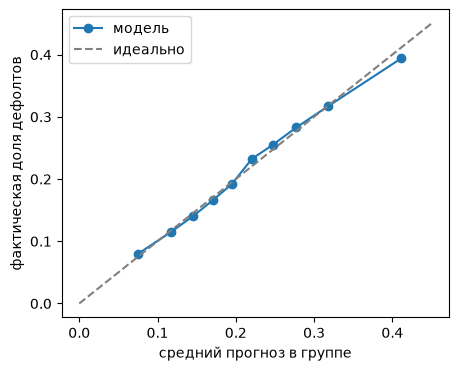

,прогноз,факт
группа,,
1,0.075,0.080
2,0.117,0.114
3,0.146,0.141
4,0.171,0.166
5,0.195,0.192
6,0.220,0.232
7,0.247,0.255
8,0.277,0.283
9,0.318,0.317


In [10]:
# qcut режет заявки на 10 групп одинакового размера по прогнозу: 1 - самые надёжные, 10 - самые рискованные
группы = pd.qcut(p_oof, 10, labels=False)
# в каждой группе: средний прогноз модели и реальная доля дефолтов
калибровка = (pd.DataFrame({"группа": группы + 1, "прогноз": p_oof, "факт": y.values})
              .groupby("группа").mean())

# график: по x что модель обещала, по y что было на самом деле. серая пунктирная линия - идеал
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(калибровка["прогноз"], калибровка["факт"], "o-", label="модель")
ax.plot([0, 0.45], [0, 0.45], "--", color="grey", label="идеально")
ax.set_xlabel("средний прогноз в группе")
ax.set_ylabel("фактическая доля дефолтов")
ax.legend()
plt.show()

калибровка.round(3)

Точки почти на диагонали, т.е. вероятностям можно верить как есть. Логрегрессия как раз и обучается подбирать вероятность а не только порядок

### Шаг 8. Правило "одобрить или отказать"

Для каждой заявки:

* одобряем: с вероятностью `1 - p` клиент платит и банк получает `доход`, с вероятностью `p` дефолт и банк теряет `убыток` этой заявки
* отказываем: 0

**Ожидаемая прибыль = (1 - p) × доход - p × убыток.** Одобряю если она больше нуля

Главное: убыток у каждой заявки свой. Если кредит маленький относительно цены машины, залог покроет почти всё и такую заявку можно одобрить даже при высоком риске. Единый порог по вероятности ("одобряем если p < 15%") это не учитывает

Проверяю на out-of-fold прогнозах. Сравниваю правило ожидаемой прибыли с множителем `k` при убытке (k = 1 чистая формула, k > 1 осторожнее, k < 1 рискованнее) и единые пороги по p.
Деньги пересчитаны на 2 000 заявок, чтобы было сравнимо с тестом

In [11]:
# считает деньги по формуле из задания для любого набора решений
# одобрить - True/False по каждой заявке, ответ - был ли дефолт, потеря - убыток по каждой заявке
# одобрили и заплатил -> +ДОХОД, одобрили и дефолт -> минус убыток, отказали -> 0
def деньги(одобрить, ответ, потеря):
    одобрить = np.asarray(одобрить).astype(bool)
    ответ = np.asarray(ответ)
    return ДОХОД * (одобрить & (ответ == 0)).sum() - потеря[одобрить & (ответ == 1)].sum()


на_2000 = 2000 / len(data)   # множитель, чтобы перевести деньги с 60 000 заявок на 2 000
L = loss_train.values        # убыток по каждой обучающей заявке
строки = []

# вариант 1: правило ожидаемой прибыли с разным k. k=1 - чистая формула
for k in [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.5]:
    реш = (1 - p_oof) * ДОХОД - k * p_oof * L > 0      # True = одобряем
    строки.append({"правило": "ожидаемая прибыль, k = %.1f" % k,
                   "одобрено, %": 100 * реш.mean(), "деньги на 2 000": деньги(реш, y, L) * на_2000})

# вариант 2: один порог для всех, одобряем если вероятность дефолта меньше t
for t in [0.10, 0.12, 0.14, 0.16, 0.18, 0.20]:
    реш = p_oof < t
    строки.append({"правило": "единый порог p < %.2f" % t,
                   "одобрено, %": 100 * реш.mean(), "деньги на 2 000": деньги(реш, y, L) * на_2000})

сравнение = pd.DataFrame(строки)
сравнение.round(1)

,правило,"одобрено, %",деньги на 2 000
0,"ожидаемая прибыль, k = 0.7",47.8,814677.8
1,"ожидаемая прибыль, k = 0.8",43.0,888717.4
2,"ожидаемая прибыль, k = 0.9",39.1,918932.3
3,"ожидаемая прибыль, k = 1.0",36.0,929278.5
4,"ожидаемая прибыль, k = 1.1",33.3,920380.1
5,"ожидаемая прибыль, k = 1.2",31.0,908500.7
6,"ожидаемая прибыль, k = 1.3",29.1,888002.2
7,"ожидаемая прибыль, k = 1.5",26.2,845764.9
8,единый порог p < 0.10,10.0,338539.7
9,единый порог p < 0.12,16.0,486430.2


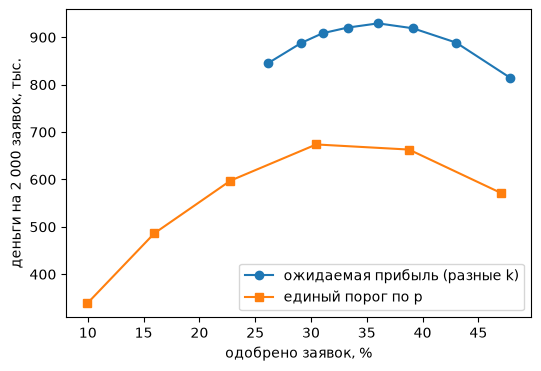

In [12]:
# то же сравнение графиком: по x сколько одобряем, по y сколько зарабатываем
# ev - строки с правилом ожидаемой прибыли, th - строки с единым порогом
fig, ax = plt.subplots(figsize=(6, 4))
ev = сравнение[сравнение["правило"].str.startswith("ожид")]
th = сравнение[сравнение["правило"].str.startswith("един")]
ax.plot(ev["одобрено, %"], ev["деньги на 2 000"] / 1000, "o-", label="ожидаемая прибыль (разные k)")
ax.plot(th["одобрено, %"], th["деньги на 2 000"] / 1000, "s-", label="единый порог по p")
ax.set_xlabel("одобрено заявок, %")
ax.set_ylabel("деньги на 2 000 заявок, тыс.")
ax.legend()
plt.show()

Лучше всего работает чистая формула, `k = 1`. Логично: вероятности откалиброваны (шаг 7), подгонять ничего не нужно. При k около 1 деньги почти те же, т.е. правило устойчивое. Единые пороги проигрывают заметно: лучший из них ~674 тыс против ~929 тыс

Итог: **одобряю если (1 - p) × доход > p × убыток.**

### Шаг 9. Финальная модель и прогноз по тесту

Обучаю ту же модель на всех 60 000 заявках (больше данных, точнее доли по кодам) и считаю вероятности и решения для своих 2 000

In [13]:
# учу на всех 60 000 и сразу предсказываю для теста
# p_test - вероятность дефолта по каждой из 2 000 заявок (это пойдёт в файл сдачи)
p_test, модель, признаки = обучить_и_предсказать(data, y, test, вернуть_модель=True)

# правило из шага 8: одобряю если ожидаемая прибыль > 0
убыток_test = убыток(test).values
ожидаемая_прибыль = (1 - p_test) * ДОХОД - p_test * убыток_test
decisions = (ожидаемая_прибыль > 0).astype(int)   # 1 = одобрить, 0 = отказать (тоже в файл сдачи)

# проверки: средняя вероятность в тесте должна быть близка к доле дефолтов в обучении (~0.22)
print("Признаков в модели:", len(признаки))
print("Средняя вероятность дефолта в тесте: %.3f (в обучении %.3f)" % (p_test.mean(), y.mean()))
print("Одобрено: %d из %d (%.1f %%)" % (decisions.sum(), len(decisions), 100 * decisions.mean()))
print("Ожидаемые деньги по одобренным (по прогнозу модели): %.0f" % ожидаемая_прибыль[decisions == 1].sum())

Признаков в модели: 119
Средняя вероятность дефолта в тесте: 0.218 (в обучении 0.217)
Одобрено: 727 из 2000 (36.4 %)
Ожидаемые деньги по одобренным (по прогнозу модели): 926438


Кого в итоге одобряю, по доле кредита в цене машины. Хорошо видно как правило учитывает размер убытка:

In [14]:
# режу заявки теста на корзины по доле кредита в цене машины: до 55%, 55-65% и тд
доля = test["сумма_кредита"] / test["цена_машины"]
корзина = pd.cut(доля, [0, 0.55, 0.65, 0.75, 0.85, 1.0])
# по каждой корзине: сколько заявок, средний риск, средний убыток и какую долю одобрили
(pd.DataFrame({"кредит к цене": корзина, "заявок": 1, "средняя p": p_test,
               "средний убыток при дефолте": убыток_test, "одобрено, %": 100 * decisions})
 .groupby("кредит к цене", observed=True)
 .agg({"заявок": "sum", "средняя p": "mean", "средний убыток при дефолте": "mean", "одобрено, %": "mean"})
 .round(3))

,заявок,средняя p,средний убыток при дефолте,"одобрено, %"
кредит к цене,,,,
"(0.0, 0.55]",162,0.127,0.000,100.000
"(0.55, 0.65]",264,0.172,4581.015,87.121
"(0.65, 0.75]",633,0.207,12073.069,42.970
"(0.75, 0.85]",723,0.252,17548.530,8.022
"(0.85, 1.0]",218,0.259,22090.517,2.294


## Файл сдачи

Ячейка ниже собирает `ФАМИЛИЯ_ИО_predictions.csv`. Формат одинаков у всех,
поэтому код готовый — выполните ячейку, менять её не требуется.
`ФАМИЛИЯ_ИО` и `ВАРИАНТ` задаются в преамбуле, а кроме них к этому
моменту у вас должны быть три величины:

| Имя | Что это |
|---|---|
| `test` | таблица вашего теста, со столбцом `клиент` |
| `p_test` | вероятности дефолта по заявкам теста |
| `decisions` | ваши решения: 1 — одобрить, 0 — отказать |

Получится файл с четырьмя столбцами:

```
вариант,клиент,вероятность,одобрить
7,556231,0.365680,0
7,608914,0.154443,1
```

In [15]:
## ── файл сдачи ─────────────────────────────────────────────────────
predictions = pd.DataFrame({
    "вариант": ВАРИАНТ,
    "клиент": test["клиент"].values,
    "вероятность": np.round(p_test, 6),
    "одобрить": np.asarray(decisions).astype(int),
})
predictions.to_csv(f"{ФАМИЛИЯ_ИО}_predictions.csv", index=False, encoding="utf-8")

## ── проверка перед сдачей ──────────────────────────────────────────
errors = []
if len(predictions) != 2000:
    errors.append("в файле %d строк, а в тесте 2 000 заявок" % len(predictions))
if predictions["клиент"].duplicated().any():
    errors.append("один и тот же клиент встречается несколько раз")
if not predictions["вероятность"].between(0, 1).all() or predictions["вероятность"].isna().any():
    errors.append("вероятности должны быть числами от 0 до 1 без пропусков")
if not set(predictions["одобрить"].unique()) <= {0, 1}:
    errors.append("столбец «одобрить» должен содержать только 0 и 1")
if not isinstance(ВАРИАНТ, int) or not 1 <= ВАРИАНТ <= 57:
    errors.append("номер варианта должен быть числом от 1 до 57")

print("Строк в файле: %d" % len(predictions))
print("Одобрено: %d (%.0f %%)"
      % (predictions["одобрить"].sum(), 100 * predictions["одобрить"].mean()))
print("Проверка: " + ("всё в порядке" if not errors else "; ".join(errors)))

predictions.head()

Строк в файле: 2000
Одобрено: 727 (36 %)
Проверка: всё в порядке


,вариант,клиент,вероятность,одобрить
0,48,616613,0.169855,0
1,48,627912,0.122530,1
2,48,458113,0.360111,0
3,48,595751,0.122569,1
4,48,500280,0.058007,1


## Обоснование

Дайте ответы на следующие вопросы:

1. **Что вы сделали с данными и почему.** Какие столбцы преобразовали,
   добавили или отбросили и что это дало на валидации.
2. **Как вы принимали решение одобрить или отказать.** Откуда взялось
   ваше правило и почему вы считаете его верным.
3. **Чего вы ждёте на тесте.** Какое качество и какие деньги, и почему
   результат может оказаться хуже, чем на валидации.

### 1. Что я сделала с данными и почему

* Даты перевела в числа: возраст заёмщика на момент выдачи, день и месяц выдачи. Год рождения там двумя цифрами, `00`-`18` считаю 2000-ми
* Сроки типа `3yrs 6mon` в месяцы
* Суммы (остатки, лимиты, платежи) через логарифм - без него несколько огромных значений тянут всю регрессию. Отрицательные остатки (их ~100) оставила со знаком
* Добавила доли: кредит к цене, доля просроченных и активных счетов, остаток к выданному, флаг "была просрочка" и долю долга которую не покроет машина
* Описание бюро свела к букве рейтинга + "нет истории" / "не оценён", пропуски в занятости отдельным флагом
* Коды (отделение, салон, марка, индекс, регион, сотрудник, дата выдачи) заменила сглаженной долей дефолтов. Для обучающих строк считала её по другим частям данных, иначе строка видит свой ответ. **Это дало больше всего**: ROC-AUC на кросс-валидации с 0,626 до 0,655
* Сплайны для возраста, доли кредита, скора и пары других признаков: ещё чуть-чуть, итог 0,6565
* `клиент` не использую

Модель - логрегрессия на стандартизованных признаках, `C = 0.3`

### 2. Как я принимала решение

Одобряю если ожидаемая прибыль больше нуля:

**(1 - p) × 2 400 - p × max(сумма_кредита - 0,55 × цена_машины, 0) > 0**

Это прямо из формулы денег в задании, отказ даёт 0. Убыток у каждой заявки свой, поэтому заявку с маленьким кредитом относительно цены машины выгодно одобрить даже при высоком p, а если кредит почти равен цене машины - нужен очень низкий p

Почему думаю что это верно: вероятности откалиброваны (шаг 7), на out-of-fold прогнозах эта формула дала больше всех денег (~929 тыс на 2 000 заявок), а k = 0,9 и 1,1 почти столько же. Лучший единый порог по p даёт ~674 тыс. Одобрить всех = минус 2,6 млн

### 3. Чего жду на тесте

ROC-AUC примерно 0,65-0,66 (на валидации 0,6565, но между частями разброс ~0,009, так что на 2 000 заявках может гулять на 0,01-0,02).
Деньги около 900 тыс: одобрено 727 из 2 000, модель сама ждёт по ним ~926 тыс

Хуже может быть потому что:
* 2 000 заявок немного, а один дефолт съедает доход примерно с пяти хороших клиентов. Пара лишних крупных дефолтов и минус сотня тысяч
* доли дефолтов по редким салонам и сотрудникам неточные, а 1-2% кодов теста в обучении вообще нет
* в тесте нет пропусков в занятости, а в обучении их 13%, т.е. выборки чуть разные
* если модель на тесте недооценит риск, банк одобрит лишних